# From registered tables to one per-cell table

Registration is not the end of the SMINT workflow. Once spatial metabolomics
(SM) pixels sit in the spatial transcriptomics (ST) coordinate frame, every
ST cell can be given the metabolite signal measured around it. The result is
one table with a row per cell: its position, its transcripts and its
metabolites.

This tutorial does that join in Python on the Sample 2 output of
[Tutorial 3](../03_sequential_registration/). It mirrors the R template
`integration/metabolomics_integration.R` (see [R integration](../../r_integration/)):
draw a **20 µm** circle around each ST cell centroid, collect the SM pixels
that fall inside it, and average each m/z column over those pixels.

**You need:** the output of Tutorial 3, `registered/sample2_sm_transformed.csv`
(run Tutorial 3 first, from the same folder), and the SMINT tutorial data.
Runs in seconds on a laptop; no GPU, Cellpose or STalign needed.

**Download this notebook:** [05_integration.ipynb](05_integration.ipynb)

> **What the tutorial data holds.** The shipped Sample 2 files are
> de-identified: ST cell **coordinates only** (no gene counts) and a random
> quarter of the MALDI pixels, **coordinates only** (no m/z intensities). The
> join below is the same one you run on a full export; here the per-cell value
> it can show is how many SM pixels each cell received. On your own data the
> same code averages every m/z column.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PatchCollection
from matplotlib.patches import Circle
from scipy.spatial import cKDTree

ST, SM = "#2b6cb0", "#d53f8c"
RADIUS = 20.0   # µm, as in integration/metabolomics_integration.R

## 1. Load the two tables

Both tables are now in the same frame: the ST cell centroids (`x_final`,
`y_final`, µm) and the registered SM pixels (`x_transformed`,
`y_transformed`, written by `register_sm_to_st(..., orientation="stalign")`).

In [2]:
st = pd.read_csv("data/sample2_st_z2.csv")
st.insert(0, "cell_id", [f"cell_{i:05d}" for i in range(1, len(st) + 1)])
sm = pd.read_csv("registered/sample2_sm_transformed.csv")

st_xy = st[["x_final", "y_final"]].to_numpy()
sm_xy = sm[["x_transformed", "y_transformed"]].to_numpy()
print(f"{len(st):,} ST cells, {len(sm):,} registered SM pixels")
sm.head()

53,622 ST cells, 115,502 registered SM pixels


,x,y,x_transformed,y_transformed
0,6900.0,6320.0,9020.876110,7442.943055
1,6900.0,6330.0,9019.913540,7455.526516
2,6900.0,6340.0,9018.949889,7468.112856
3,6900.0,6350.0,9017.985156,7480.702079
4,6900.0,6360.0,9017.019339,7493.294189


On a full MALDI export the SM table also has one column per m/z value.
`read_sm_matrix` prefixes those numeric headers with `X` (`72.0796` →
`X72.0796`), so they are easy to pick out:

In [3]:
mz_cols = [c for c in sm.columns if c.startswith("X")]
print(f"{len(mz_cols)} m/z columns in this table")

0 m/z columns in this table


## 2. Join SM pixels to cells within 20 µm

`cKDTree.query_ball_point` returns, for every ST cell, the indices of the SM
pixels within the radius. That is the Python equivalent of
`st_join(st_buffer(st_centroid(cells), 20), sm_points)` in the R template.
Flatten it into a long table of (cell, pixel) pairs:

In [4]:
neighbours = cKDTree(sm_xy).query_ball_point(st_xy, r=RADIUS)
n_pixels = np.array([len(n) for n in neighbours])
pair_cell = np.repeat(np.arange(len(st)), n_pixels)
pair_pixel = np.concatenate([np.asarray(n, dtype=int) for n in neighbours])

print(f"{len(pair_cell):,} (cell, SM pixel) pairs")
print(f"{(n_pixels > 0).mean():.0%} of ST cells have at least one SM pixel within {RADIUS:.0f} µm")
print(f"median SM pixels per covered cell: {np.median(n_pixels[n_pixels > 0]):.0f}")

122,135 (cell, SM pixel) pairs
90% of ST cells have at least one SM pixel within 20 µm
median SM pixels per covered cell: 2


A pixel can count towards several neighbouring cells, exactly as in the R
template: each cell gets the average of the metabolite signal around it.
Cells outside the MALDI-imaged area get no pixels; keep them (with missing
metabolite values) or drop them, depending on your analysis.

## 3. Build the per-cell table

Average every m/z column over each cell's pixels and add the pixel count and
the distance to the nearest SM pixel as quality columns:

In [5]:
def per_cell_metabolites(sm, pair_cell, pair_pixel, mz_cols, n_cells):
    """Mean of each m/z column over the SM pixels joined to each cell."""
    joined = sm.iloc[pair_pixel][mz_cols].assign(_cell=pair_cell)
    means = joined.groupby("_cell").mean()
    return means.reindex(range(n_cells))      # cells without pixels -> NaN


nearest_um, _ = cKDTree(sm_xy).query(st_xy)
cells = st.assign(
    n_sm_pixels=n_pixels,
    nearest_sm_um=nearest_um.round(1),
)
metabolites = per_cell_metabolites(sm, pair_cell, pair_pixel, mz_cols, len(st))
cells = pd.concat([cells, metabolites.set_index(cells.index)], axis=1)

os.makedirs("integrated", exist_ok=True)
cells.to_csv("integrated/sample2_cells_with_sm.csv", index=False)
cells.head()

,cell_id,x_final,y_final,n_sm_pixels,nearest_sm_um
0,cell_00001,6481.7,1434.5,2,11.8
1,cell_00002,4333.9,2343.8,1,15.9
2,cell_00003,7009.6,2934.6,2,8.5
3,cell_00004,4712.0,6757.3,3,4.2
4,cell_00005,2718.9,7418.6,2,5.8


With a full export, `cells` has one more column per m/z value: the mean
abundance around that cell. Add the transcripts by joining the Xenium
cell-by-gene matrix on the cell ID (for example `cell_feature_matrix` read
with `scanpy.read_10x_h5`, or the counts in your Seurat or
SpatialExperiment object), and you have the cell × gene × metabolite table
the R template saves as a `SpatialExperiment`.

## 4. Look at the result

Left: every ST cell coloured by how many SM pixels it received. Right: a
300 µm window showing what the join does: each blue cell centroid collects
the pink SM pixels inside its 20 µm circle.

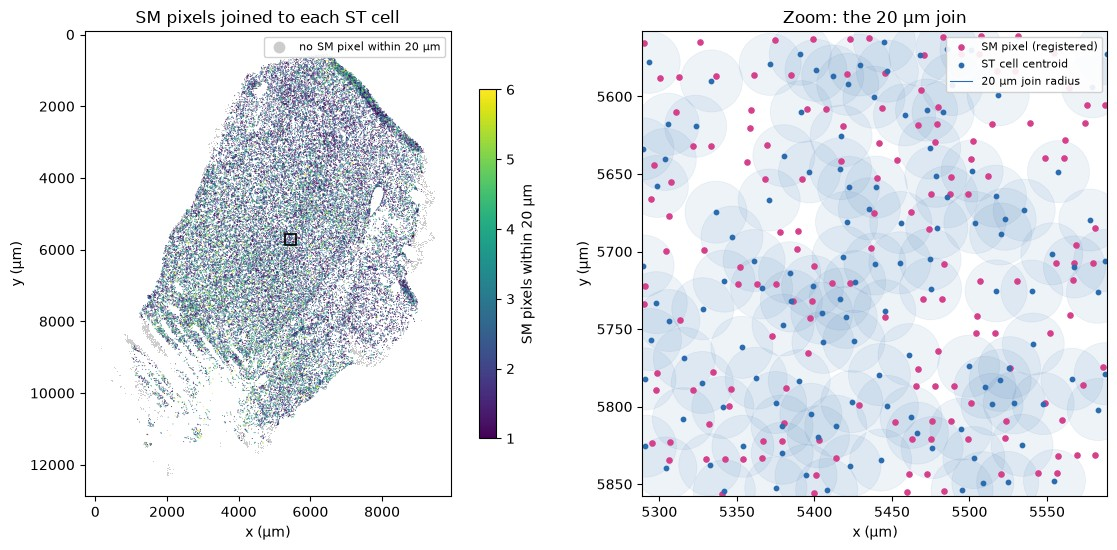

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5.6),
                                  gridspec_kw={"width_ratios": [1.15, 1]})

covered = n_pixels > 0
left.scatter(st_xy[~covered, 0], st_xy[~covered, 1], s=0.5, c="0.8", lw=0,
             label="no SM pixel within 20 µm")
im = left.scatter(st_xy[covered, 0], st_xy[covered, 1], s=0.5, c=n_pixels[covered],
                  cmap="viridis", lw=0, vmax=np.percentile(n_pixels[covered], 99))
fig.colorbar(im, ax=left, shrink=0.75, label="SM pixels within 20 µm")
left.set(aspect="equal", title="SM pixels joined to each ST cell",
         xlabel="x (µm)", ylabel="y (µm)")
left.invert_yaxis()
left.legend(loc="upper right", markerscale=12, fontsize=8, framealpha=0.9)

# Zoom window centred on a well-covered cell near the middle of the section
centre = st_xy[covered][np.argmin(np.linalg.norm(st_xy[covered] - np.median(st_xy[covered], 0), axis=1))]
(x0, y0), w = centre - 150, 300
left.add_patch(plt.Rectangle((x0, y0), w, w, fill=False, ec="k", lw=1.2))

in_win = lambda p: (p[:, 0] > x0) & (p[:, 0] < x0 + w) & (p[:, 1] > y0) & (p[:, 1] < y0 + w)
c_win, s_win = st_xy[in_win(st_xy)], sm_xy[in_win(sm_xy)]
right.add_collection(PatchCollection([Circle(p, RADIUS) for p in c_win],
                                     facecolor=ST, alpha=0.08, edgecolor=ST, lw=0.6))
right.scatter(s_win[:, 0], s_win[:, 1], s=14, c=SM, label="SM pixel (registered)")
right.scatter(c_win[:, 0], c_win[:, 1], s=10, c=ST, label="ST cell centroid")
right.plot([], [], color=ST, lw=0.8, label="20 µm join radius")
right.set(xlim=(x0, x0 + w), ylim=(y0 + w, y0), aspect="equal",
          title="Zoom: the 20 µm join", xlabel="x (µm)", ylabel="y (µm)")
right.legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

The SM pixels sit on a 10 µm grid, so a 20 µm circle can hold up to about
12 of them (π · 20² / 10²) on a full export; the tutorial file keeps a random
quarter, hence the median of 2 here. Cells at the edge of the MALDI-imaged area get fewer pixels, and
cells outside it none: filter on `n_sm_pixels` (for example, keep cells with
at least half the typical count) before you compare metabolite levels
between cells.

## Do it in R instead

The same join with `sf`, starting from the registered table and your ST cell
polygons, is in `integration/metabolomics_integration.R`; its output is a
`SpatialExperiment` with metabolites and log-normalised transcripts as
features. See [R integration](../../r_integration/).

## Next steps

- The whole workflow in one page: [The SMINT workflow](../../concepts/workflow/).
- Register your own sections: [Alignment](../../alignment/).
- Assign transcripts to segmented cells and other R steps: [R integration](../../r_integration/).
- Run it on the cluster: [Running on HPC](../../hpc_deployment/).